# 02 · Giảm chiều bằng Kernel PCA RBF

Phần phân tích của Tuananh dùng tập development để mô tả dữ liệu và khảo sát quan hệ với nhãn `Response`. Pipeline tiền xử lý học từ đặc trưng của development. Nhãn chỉ dùng để lập bảng và tô màu sau khi giảm chiều. Tập test cuối được giữ riêng.

In [1]:
import json
import sys
from hashlib import sha256
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

root = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "src" / "dim_reduction.py").is_file()
)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src import config
from src.dim_reduction import (
    compute_kernel_explained_variance,
    fit_kernel_pca_rbf,
    generate_components_statistics,
)
from src.experiment_preprocessing import make_feature_pipeline

sns.set_theme(style="whitegrid", context="notebook")
palette = {0: "#28679A", 1: "#BF5E24"}
config.FIGURES_DIM_REDUCTION_DIR.mkdir(parents=True, exist_ok=True)
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
manifest = json.loads((config.SPLITS_DIR / "manifest.json").read_text(encoding="utf-8"))
data = (config.SPLITS_DIR / "development.csv").read_bytes()
if sha256(data).hexdigest() != manifest["files_sha256"]["development.csv"]:
    raise ValueError("development.csv không khớp manifest tập chia.")

development = pd.read_csv(BytesIO(data))
X = development[manifest["features"]]
response = development[manifest["target"]]
X_encoded = make_feature_pipeline(X).fit_transform(X)
print(f"{len(X):,} mẫu development, {X_encoded.shape[1]} đặc trưng sau mã hóa.")
print(f"Response=1: {response.sum():,} mẫu ({response.mean():.1%}).")

1,788 mẫu development, 37 đặc trưng sau mã hóa.
Response=1: 267 mẫu (14.9%).


## Phương sai trong không gian kernel

Giữ 6 thành phần. Chọn `gamma = 1 / d` theo mặc định của kernel RBF, với `d` là số đặc trưng sau mã hóa. Cách chọn này dùng số chiều đầu vào.

Với `n` mẫu, scikit-learn định tâm ma trận kernel. Phương sai thành phần thứ `i` bằng `λᵢ / (n − 1)`. Tỷ lệ của thành phần là `λᵢ / trace(Kc)`, trong đó `trace(Kc)` là tổng toàn bộ trị riêng của kernel đã định tâm.

In [3]:
n_components = 6
gamma = 1 / X_encoded.shape[1]
kpca = fit_kernel_pca_rbf(X_encoded, n_components=n_components, gamma=gamma)
coordinates = kpca.transform(X_encoded)
variance, ratio = compute_kernel_explained_variance(kpca, len(X_encoded))
cumulative = np.cumsum(ratio)

components = [f"KPCA{i}" for i in range(1, n_components + 1)]
scores = pd.DataFrame(coordinates, columns=components)
print(f"gamma = {kpca.gamma_:.6f}")
print(f"{n_components} thành phần giữ {cumulative[-1]:.2%} phương sai kernel.")

gamma = 0.027027
6 thành phần giữ 39.17% phương sai kernel.


,Mean,Std,Skewness,kernel_variance,kernel_variance_ratio,cumulative_ratio,median_response_0,median_response_1,point_biserial_r
component,,,,,,,,,
KPCA1,0.0,0.3416,0.0302,0.1167,0.1672,0.1672,-0.0797,0.2927,0.2112
KPCA2,-0.0,0.2245,0.3059,0.0504,0.0723,0.2395,0.0082,-0.1445,-0.1389
KPCA3,-0.0,0.1954,0.1888,0.0382,0.0547,0.2942,-0.0346,0.1526,0.2923
KPCA4,0.0,0.1647,-0.0133,0.0271,0.0389,0.3331,-0.0114,0.0312,0.1610
KPCA5,-0.0,0.1489,0.3075,0.0222,0.0318,0.3649,-0.0407,0.0857,0.1443
KPCA6,0.0,0.1368,0.0088,0.0187,0.0268,0.3917,-0.0068,0.0148,0.1168


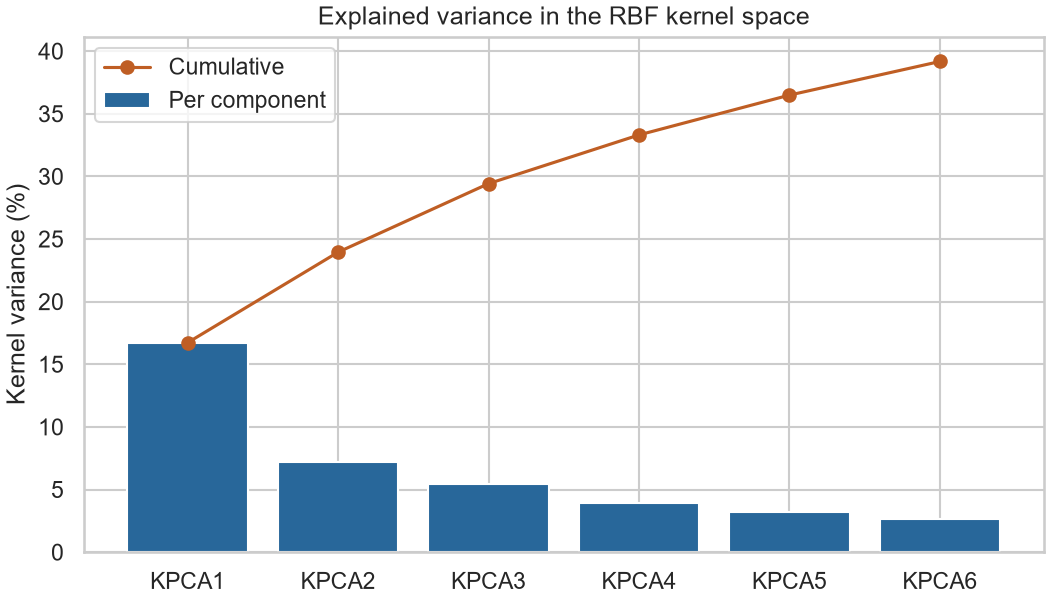

In [4]:
statistics = generate_components_statistics(coordinates, n_components)
statistics.index = pd.Index(components, name="component")
statistics["kernel_variance"] = variance
statistics["kernel_variance_ratio"] = ratio
statistics["cumulative_ratio"] = cumulative
medians = scores.groupby(response).median().T
statistics["median_response_0"] = medians[0]
statistics["median_response_1"] = medians[1]
statistics["point_biserial_r"] = scores.corrwith(response)
statistics.to_csv(config.TABLES_DIR / "kpca_component_statistics.csv")
display(statistics.round(4))

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.bar(components, ratio * 100, color=palette[0], label="Per component")
ax.plot(components, cumulative * 100, color=palette[1], marker="o", label="Cumulative")
ax.set(title="Explained variance in the RBF kernel space", ylabel="Kernel variance (%)")
ax.legend()
fig.savefig(config.FIGURES_DIM_REDUCTION_DIR / "kpca_explained_variance.png", dpi=config.FIGURE_DPI)
plt.show()
plt.close(fig)

## Quan hệ với Response

Biểu đồ cặp và boxplot dùng 4 thành phần đầu. Mỗi biểu đồ phân biệt khách hàng hưởng ứng (`Response=1`) và không hưởng ứng (`Response=0`). Bảng ghi trung vị của hai nhóm và hệ số tương quan point-biserial giữa từng thành phần và nhãn.

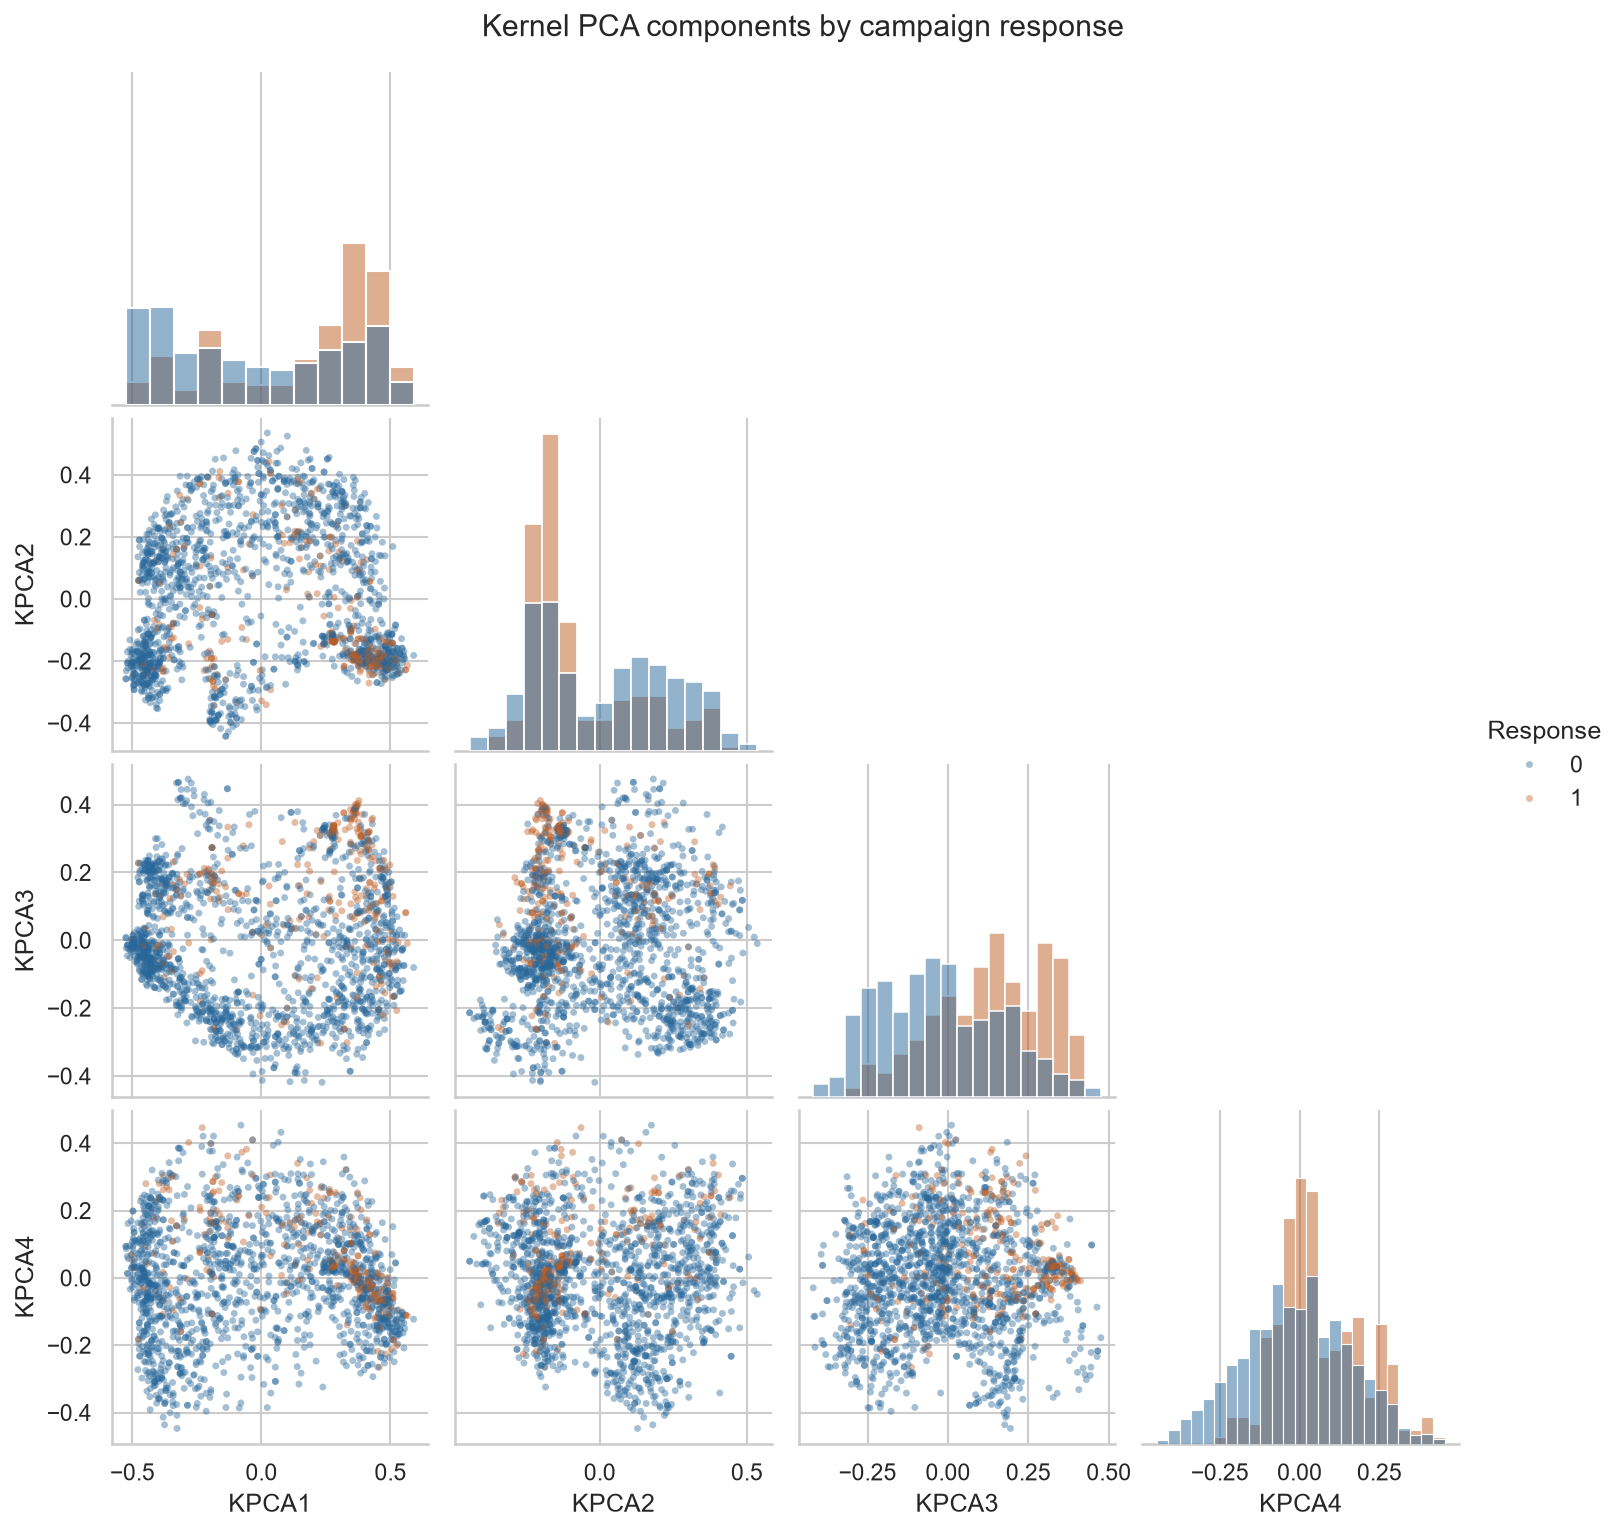

In [5]:
displayed_components = components[:4]
visual = scores[displayed_components].assign(Response=response)
grid = sns.pairplot(
    visual, hue="Response", hue_order=[0, 1], palette=palette, corner=True,
    diag_kind="hist", diag_kws={"stat": "density", "common_norm": False},
    plot_kws={"alpha": 0.42, "s": 11, "linewidth": 0},
)
grid.fig.suptitle("Kernel PCA components by campaign response", y=1.02)
grid.fig.savefig(
    config.FIGURES_DIM_REDUCTION_DIR / "kpca_pairplot.png",
    dpi=config.FIGURE_DPI, bbox_inches="tight",
)
plt.show()
plt.close(grid.fig)

KPCA3 có |r| lớn nhất trong 6 thành phần, r = 0.292.


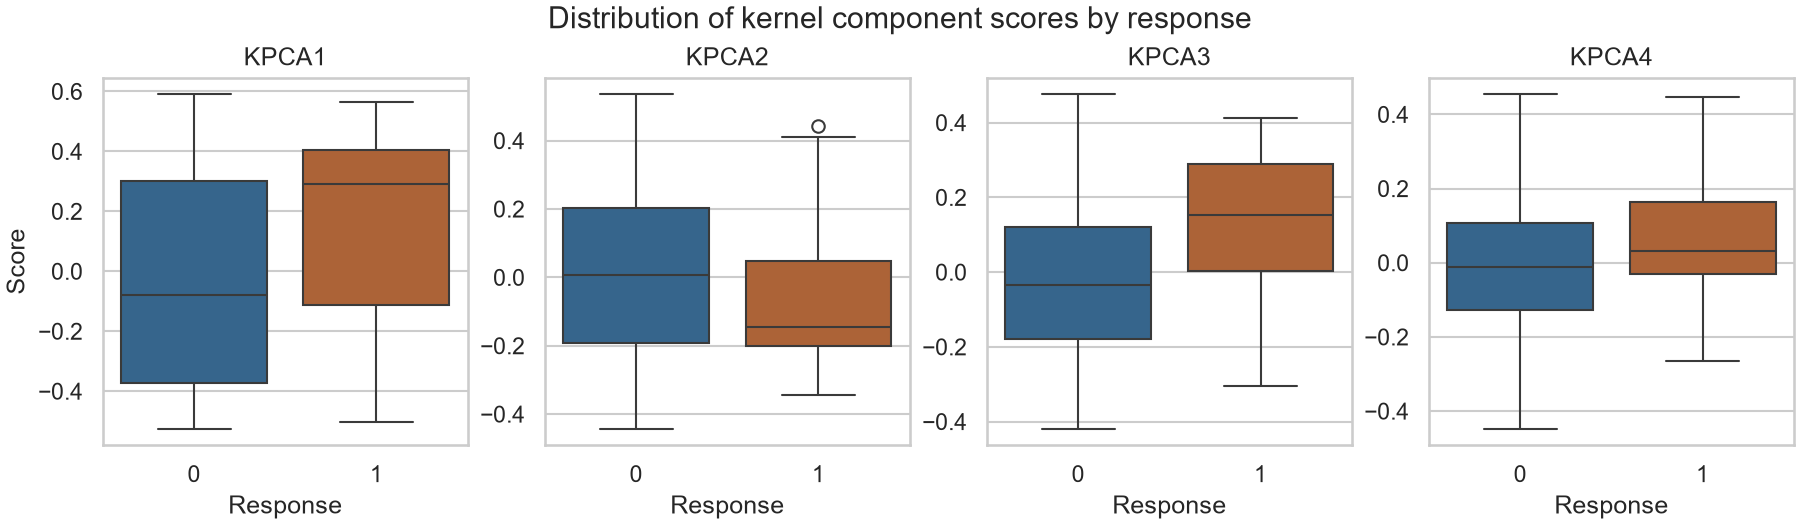

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), layout="constrained")
for ax, component in zip(axes, displayed_components):
    sns.boxplot(
        data=visual, x="Response", y=component, hue="Response",
        order=[0, 1], palette=palette, legend=False, ax=ax,
    )
    ax.set(title=component, ylabel="Score" if ax is axes[0] else "")
fig.suptitle("Distribution of kernel component scores by response")
fig.savefig(config.FIGURES_DIM_REDUCTION_DIR / "kpca_boxplot.png", dpi=config.FIGURE_DPI)
plt.show()
plt.close(fig)

strongest = statistics["point_biserial_r"].abs().idxmax()
r = statistics.loc[strongest, "point_biserial_r"]
print(f"{strongest} có |r| lớn nhất trong 6 thành phần, r = {r:.3f}.")

## Nhận xét trên tập development

Với gamma ≈ 0,02703, thành phần đầu giải thích 16,72% phương sai kernel. Sáu thành phần đầu giữ 39,17% phương sai tích lũy.

KPCA3 có tương quan với Response lớn nhất theo trị tuyệt đối trong sáu thành phần (r ≈ 0,292). Trung vị KPCA3 của nhóm hưởng ứng là 0,153, cao hơn mức −0,035 ở nhóm còn lại. Các hộp vẫn chồng lấn, nên hai nhóm có nhiều điểm số KPCA3 tương tự nhau.

## Ghép với phân tích PCA tuyến tính

Dùng cùng tập development và cách tiền xử lý để đối chiếu phân bố các thành phần theo `Response`. PCA tuyến tính tính tỷ lệ phương sai trong không gian đặc trưng đã tiền xử lý. Tỷ lệ Kernel PCA mô tả phương sai trong không gian kernel RBF.

Pipeline PCA giảm còn một phần ba số chiều cho phân loại và hồi quy được tạo bằng `make_feature_pipeline(X_train, reduce=True)` và fit riêng trên từng train.